In [1]:
import subprocess

import matplotlib.pyplot as plt
import pandas as pd
import rasterio
import xarray as xr
from rasterio.warp import Resampling

from rain2loss.download import download
from rain2loss.gis import (catchment_polygon, cell_weights, open_eobs, reproject_raster,
                           simple_mean, weighted_mean)
from rain2loss.lamah import load_lamah
from rain2loss.paths import DATA_PROCESSED, DATA_RAW

GAUGE_ID = 824
EOBS_DIR = DATA_RAW / "eobs"
DATA_PROCESSED.mkdir(exist_ok=True)
catchment = catchment_polygon(GAUGE_ID)
catchment

,ID,geometry
800,824,"POLYGON ((16.93407 50.03244, 16.92844 50.03057..."


In [2]:
EOBS_URL = "https://knmi-ecad-assets-prd.s3.amazonaws.com/ensembles/data/Grid_0.1deg_reg_ensemble/"
RR_FILE = "rr_ens_mean_0.1deg_reg_2011-2025_v33.0e.nc"
download(EOBS_URL + RR_FILE, EOBS_DIR / RR_FILE)

already there: rr_ens_mean_0.1deg_reg_2011-2025_v33.0e.nc


In [3]:
rr_cz_file = DATA_PROCESSED / "eobs_rr_cz_2011-2025.nc"
if not rr_cz_file.exists():
    open_eobs(EOBS_DIR / RR_FILE).to_netcdf(rr_cz_file)
rr = open_eobs(rr_cz_file)
rr

<xarray.DataArray 'rr' (time: 5479, latitude: 26, longitude: 70)> Size: 40MB
dask.array<open_dataset-rr, shape=(5479, 26, 70), dtype=float32, chunksize=(5479, 26, 70), chunktype=numpy.ndarray>
Coordinates:
  * time         (time) datetime64[ns] 44kB 2011-01-01 2011-01-02 ... 2025-12-31
  * latitude     (latitude) float64 208B 48.55 48.65 48.75 ... 50.85 50.95 51.05
  * longitude    (longitude) float64 560B 12.05 12.15 12.25 ... 18.85 18.95
    spatial_ref  int64 8B 0
Attributes:
    standard_name:  thickness_of_rainfall_amount
    long_name:      rainfall
    units:          mm

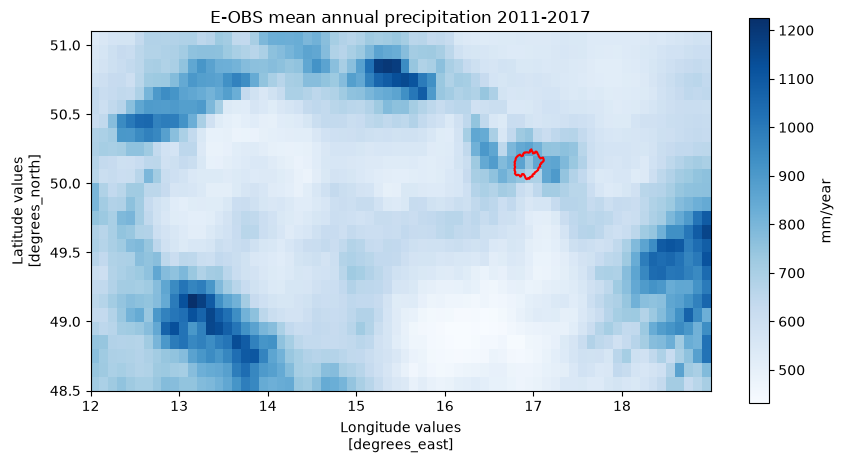

In [4]:
annual_mean = rr.sel(time=slice("2011", "2017")).groupby("time.year").sum().mean("year").compute()
fig, ax = plt.subplots(figsize=(10, 5))
annual_mean.plot(ax=ax, cmap="Blues", cbar_kwargs={"label": "mm/year"})
catchment.boundary.plot(ax=ax, color="red")
ax.set_title("E-OBS mean annual precipitation 2011-2017")
plt.show()

  lon   lat  weight
16.95 50.15   0.226
16.85 50.15   0.220
17.05 50.15   0.181
16.95 50.05   0.129
16.85 50.05   0.092
16.95 50.25   0.063
17.05 50.25   0.027
17.05 50.05   0.022
16.75 50.15   0.015
17.15 50.15   0.010
16.85 50.25   0.009
16.75 50.05   0.006


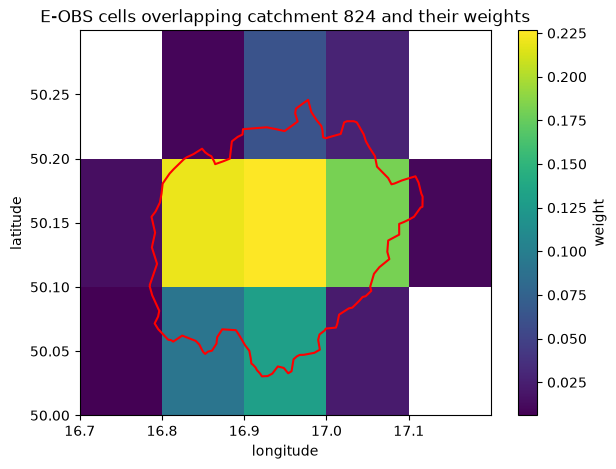

In [5]:
lon, lat, weights = cell_weights(rr, catchment)
cells = pd.DataFrame({"lon": lon, "lat": lat, "weight": weights}).sort_values("weight", ascending=False)
print(cells.round(3).to_string(index=False))

weight_map = (xr.DataArray(weights, dims="cell",
                           coords={"latitude": ("cell", lat), "longitude": ("cell", lon)})
              .set_index(cell=["latitude", "longitude"])
              .unstack("cell"))
fig, ax = plt.subplots(figsize=(7, 5))
weight_map.plot(ax=ax, cmap="viridis", cbar_kwargs={"label": "weight"})
catchment.boundary.plot(ax=ax, color="red")
ax.set_title("E-OBS cells overlapping catchment 824 and their weights")
plt.show()

In [6]:
p_weighted = weighted_mean(rr, catchment).to_series()
p_simple = simple_mean(rr, catchment).to_series()
p_era5 = load_lamah(GAUGE_ID)["prec"]
compare = pd.DataFrame({"E-OBS weighted": p_weighted, "E-OBS simple": p_simple,
                        "ERA5-Land (LamaH)": p_era5}).loc["2011":"2017"]
yearly = compare.groupby(compare.index.year)
summary = pd.DataFrame({"mean annual (mm)": yearly.sum().mean(),
                        "wet days per year (P > 1 mm)": (compare > 1).groupby(compare.index.year).sum().mean(),
                        "mean annual max day (mm)": yearly.max().mean()})
summary.round(1)

,mean annual (mm),wet days per year (P > 1 mm),mean annual max day (mm)
E-OBS weighted,796.5,128.3,40.4
E-OBS simple,797.1,129.6,40.2
ERA5-Land (LamaH),991.9,175.3,34.8


ERA5-Land shifted by -1 day: r = 0.36
ERA5-Land shifted by +0 day: r = 0.77
ERA5-Land shifted by +1 day: r = 0.13


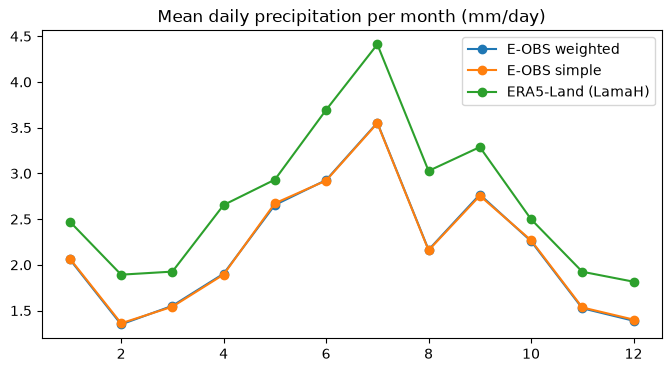

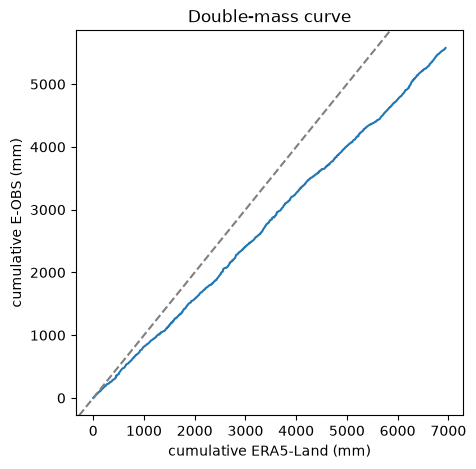

In [7]:
for lag in [-1, 0, 1]:
    r = compare["E-OBS weighted"].corr(compare["ERA5-Land (LamaH)"].shift(lag))
    print(f"ERA5-Land shifted by {lag:+d} day: r = {r:.2f}")

monthly = compare.groupby(compare.index.month).mean()
ax = monthly.plot(marker="o", figsize=(8, 4), title="Mean daily precipitation per month (mm/day)")
plt.show()

ax = compare.cumsum().plot(x="ERA5-Land (LamaH)", y="E-OBS weighted", figsize=(5, 5), legend=False)
ax.axline((0, 0), slope=1, color="grey", linestyle="--")
ax.set(xlabel="cumulative ERA5-Land (mm)", ylabel="cumulative E-OBS (mm)", title="Double-mass curve")
plt.show()

In [8]:
DEM_DIR = DATA_RAW / "dem"
base = "https://copernicus-dem-30m.s3.amazonaws.com"
tile_files = []
for n in ("N49", "N50"):
    for e in ("E016", "E017"):
        name = f"Copernicus_DSM_COG_10_{n}_00_{e}_00_DEM"
        download(f"{base}/{name}/{name}.tif", DEM_DIR / f"{name}.tif")
        tile_files.append(str(DEM_DIR / f"{name}.tif"))

xmin, ymin, xmax, ymax = catchment_polygon(GAUGE_ID, crs="EPSG:3035").buffer(2000).total_bounds
vrt = str(DATA_PROCESSED / "cop_dem.vrt")
subprocess.run(["gdalbuildvrt", "-strict", "-overwrite", vrt, *tile_files], check=True)
for method in ["near", "bilinear"]:
    subprocess.run(["gdalwarp", "-overwrite", "-t_srs", "EPSG:3035",
                    "-te", str(xmin), str(ymin), str(xmax), str(ymax), "-tr", "30", "30",
                    "-r", method, "-dstnodata", "-9999", "-co", "COMPRESS=DEFLATE", "-co", "TILED=YES",
                    vrt, str(DATA_PROCESSED / f"dem_3035_{method}.tif")], check=True)

for method in ["near", "bilinear"]:
    with rasterio.open(DATA_PROCESSED / f"dem_3035_{method}.tif") as src:
        dem = src.read(1, masked=True)
        print(f"{method}: {src.width} x {src.height} cells, {dem.min():.0f}-{dem.max():.0f} m, "
              f"empty cells: {int(dem.mask.sum())}")

    43.2 / 43.2 MB
done: Copernicus_DSM_COG_10_N49_00_E016_00_DEM.tif
    43.0 / 43.0 MB
done: Copernicus_DSM_COG_10_N49_00_E017_00_DEM.tif
    29.4 / 29.4 MB
done: Copernicus_DSM_COG_10_N50_00_E016_00_DEM.tif
    29.1 / 29.1 MB
done: Copernicus_DSM_COG_10_N50_00_E017_00_DEM.tif
near: 911 x 942 cells, 346-1423 m, empty cells: 0
bilinear: 911 x 942 cells, 346-1423 m, empty cells: 0


bilinear - nearest: mean -0.00 m, std 2.57 m, max |diff| 20.0 m


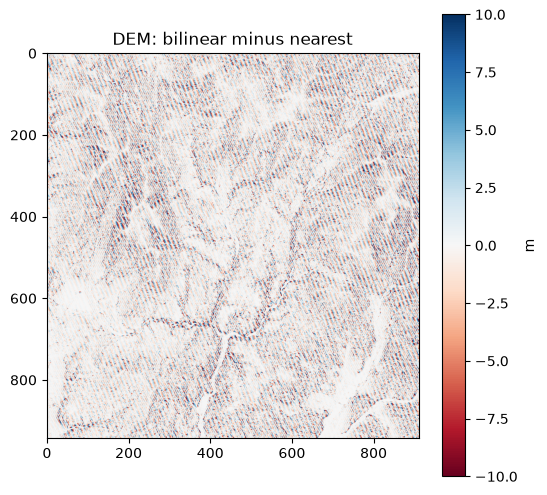

In [9]:
with rasterio.open(DATA_PROCESSED / "dem_3035_near.tif") as a, \
        rasterio.open(DATA_PROCESSED / "dem_3035_bilinear.tif") as b:
    diff = b.read(1, masked=True) - a.read(1, masked=True)
print(f"bilinear - nearest: mean {diff.mean():.2f} m, std {diff.std():.2f} m, max |diff| {abs(diff).max():.1f} m")
fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(diff, cmap="RdBu", vmin=-10, vmax=10)
plt.colorbar(im, label="m")
ax.set_title("DEM: bilinear minus nearest")
plt.show()

In [10]:
reproject_raster(DATA_PROCESSED / "dem_3035_bilinear.tif", DATA_PROCESSED / "dem_5514.tif",
                 "EPSG:5514", resolution=30, resampling=Resampling.bilinear)
with rasterio.open(DATA_PROCESSED / "dem_5514.tif") as src:
    print(src.crs, src.res, [round(v) for v in src.bounds])

EPSG:5514 (30.0, 30.0) [-578822, -1075607, -546452, -1042517]
